In [2]:
## This notebook is used to plot and save the phase diagrams based on the G-alpha parameter exploration

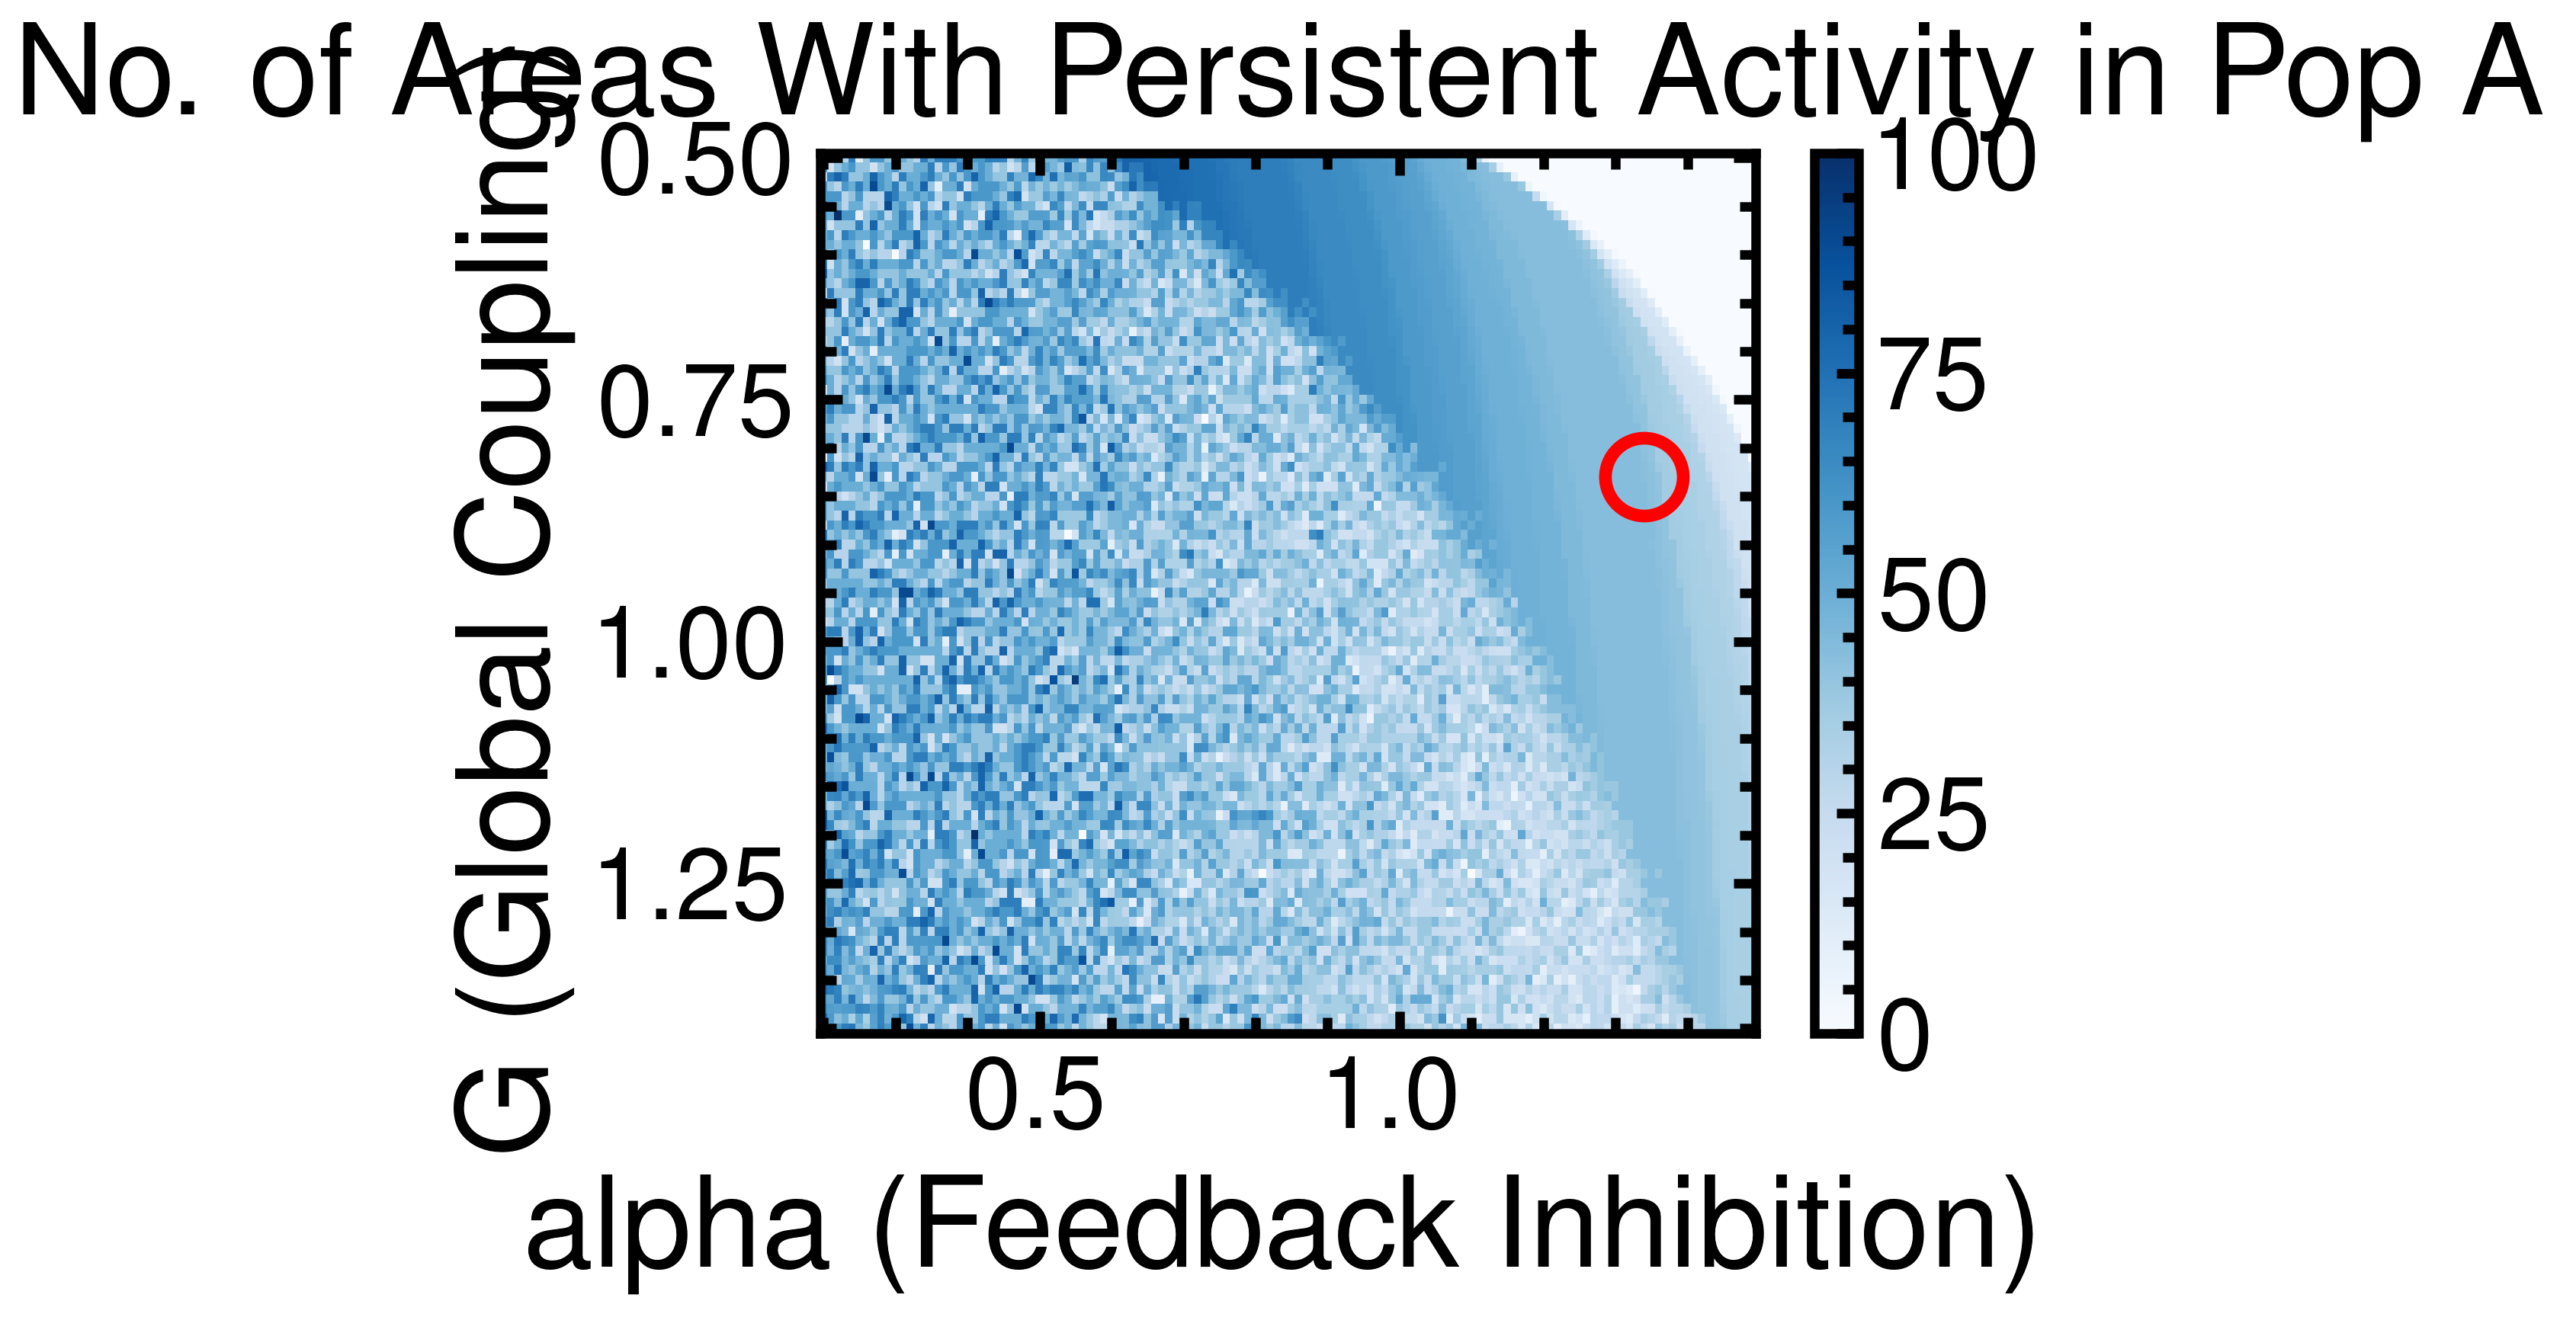

In [3]:

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.colors import LinearSegmentedColormap
plt.style.use(['science', 'nature'])

plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.title_fontsize": 16,
    "legend.fontsize": 13,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)

cmaps_phase = {
    "pop_A": LinearSegmentedColormap.from_list(
        "pop_A", ["#ffffff", "#71ac8c", "#036330"], N=256
    ),
    "pop_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#ffffff", "#AF7885", "#ab1337"], N=256
    ),
    "pop_A_minus_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#9e2440", "#ffffff", "#057b3c"], N=256
    ),
}

state_change_log_path = '/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3/persistent_activity_stats_all_runs.csv'
df = pd.read_csv(state_change_log_path, delimiter=",", skipinitialspace=True)
df = df[df['G'] <= 1.4]

col_g = "G"
col_alpha = "alpha"
col_no_persist = "Prob_NoPersist"
col_a_only = "Prob_A_Only"
col_b_only = "Prob_B_Only"
col_a_b = "Prob_A_B"
col_mean_a = "MeanAreasA_uncond"
col_mean_b = "MeanAreasB_uncond"

piv_mean_a = df.pivot(index=col_g, columns=col_alpha, values=col_mean_a)
piv_mean_b = df.pivot(index=col_g, columns=col_alpha, values=col_mean_b)
# Heatmap for Population A
plt.figure()
# Mean Areas A
plt.title("No. of Areas With Persistent Activity in Pop A")
imA = plt.pcolor(
    piv_mean_a.columns,
    piv_mean_a.index,
    piv_mean_a.values,
    cmap='Blues',
    shading='auto'
)
plt.gca().invert_yaxis()
plt.xlabel("alpha (Feedback Inhibition)")
plt.ylabel("G (Global Coupling)")
plt.colorbar(imA)

plt.scatter(
    1.34,          # x = alpha
    0.83,          # y = G
    s=150,         # marker size
    edgecolor='red', 
    facecolor='none', 
    linewidth=2,   # thickness of the circle
    label='(alpha=1.34, G=0.83)'
)

plt.show()

In [4]:
df['G'].max()

np.float64(1.4)

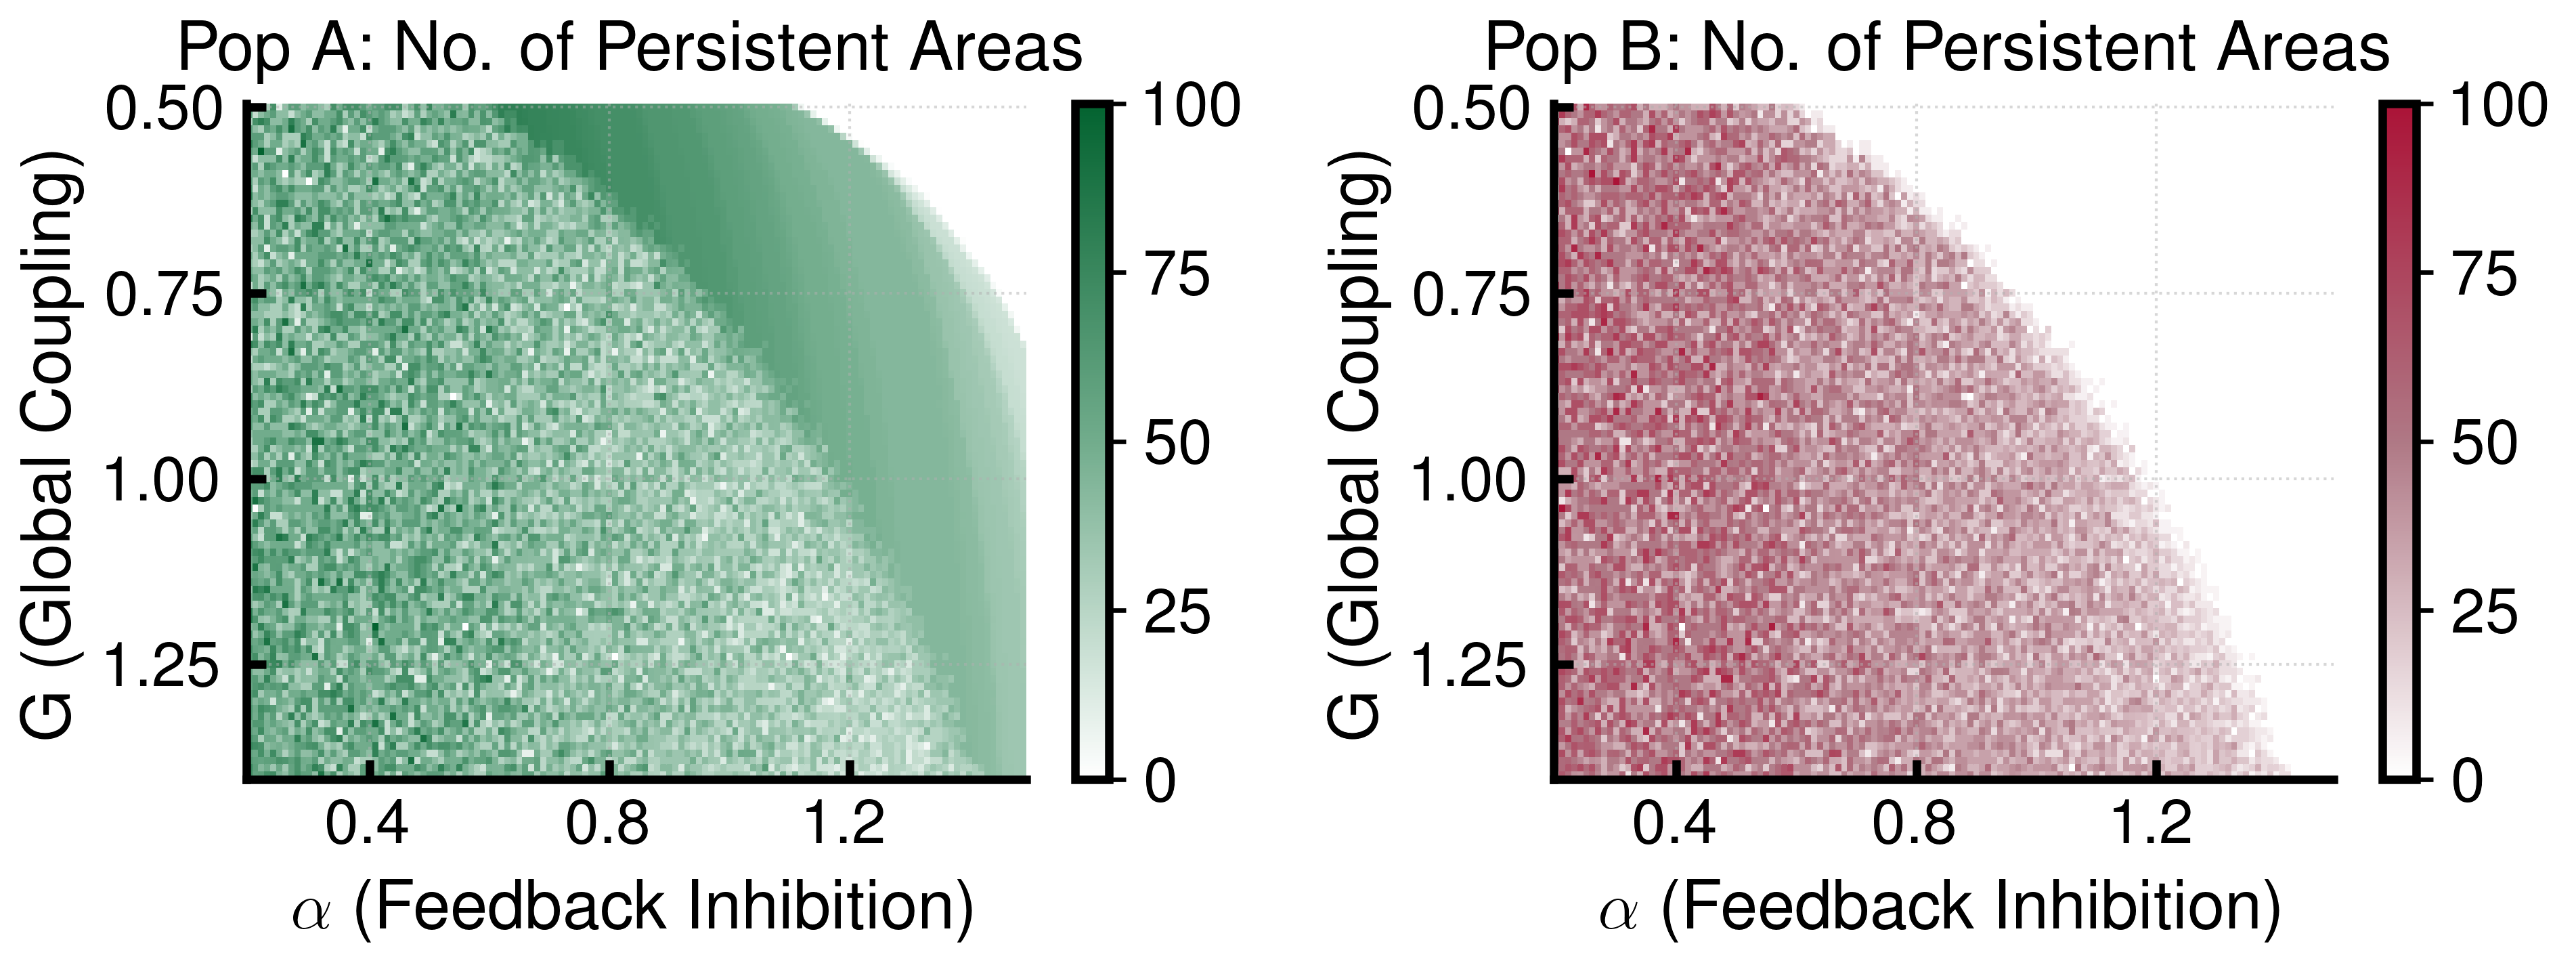

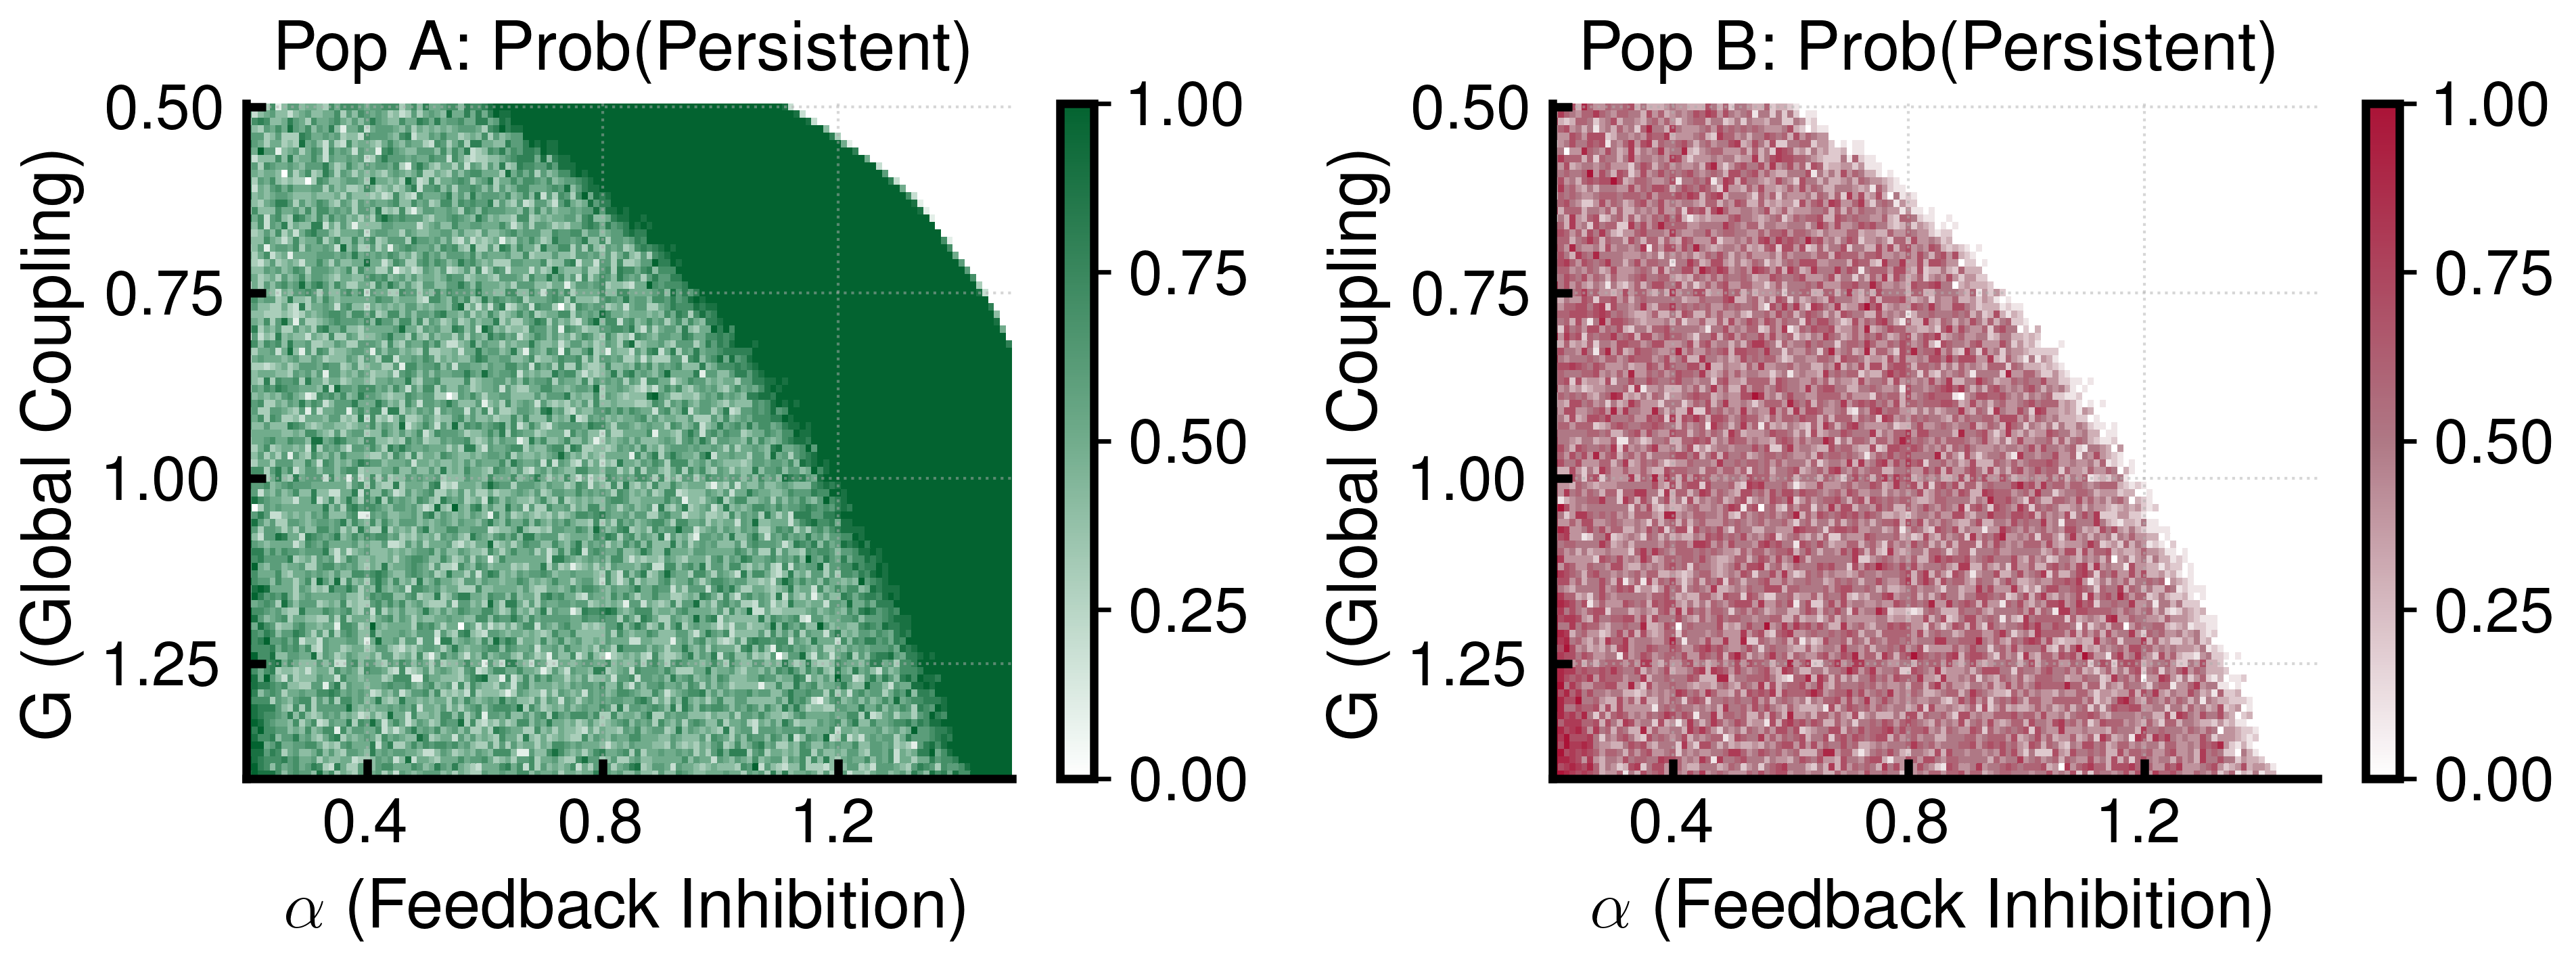

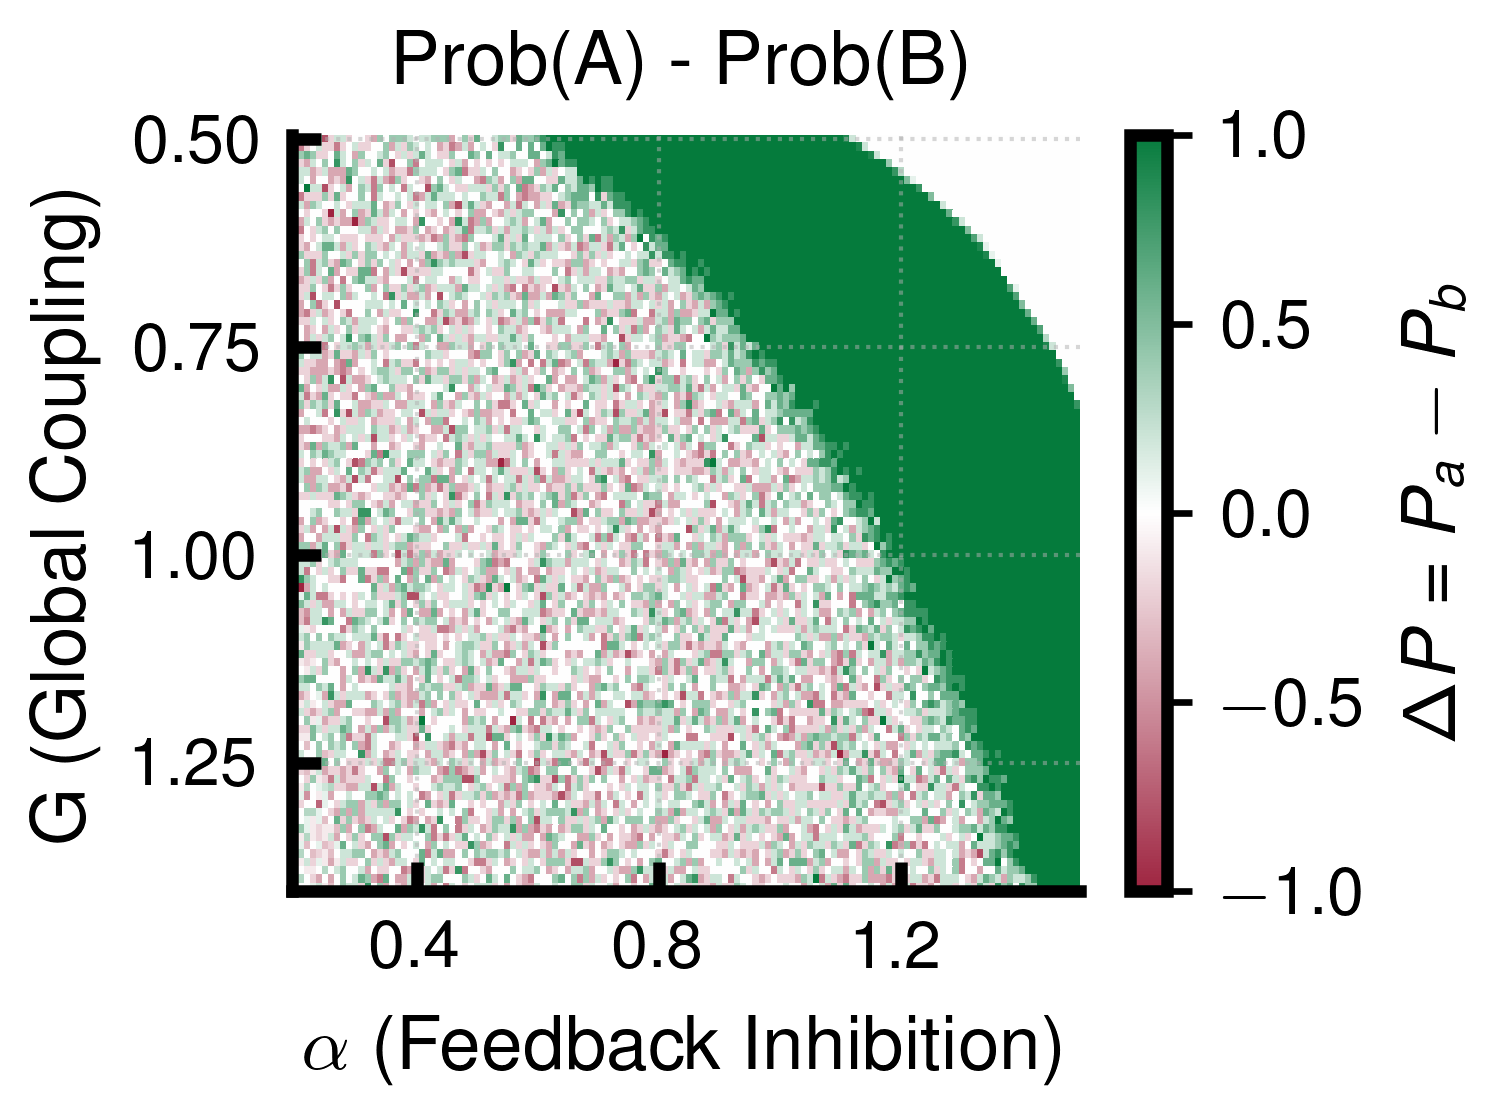

All plots generated and saved in: /home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3


In [5]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

def plot_forbidden_gap_analysis():
    csv_path = '/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3/persistent_activity_stats_all_runs.csv'
    results_dir = '/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3'
    df = pd.read_csv(csv_path, delimiter=",", skipinitialspace=True)
    df = df[df['G'] <= 1.4] # Simulation didn't work for some values above this

    col_g = "G"
    col_alpha = "alpha"
    col_no_persist = "Prob_NoPersist"
    col_a_only = "Prob_A_Only"
    col_b_only = "Prob_B_Only"
    col_a_b = "Prob_A_B"
    col_mean_a = "MeanAreasA_uncond"
    col_mean_b = "MeanAreasB_uncond"

    from matplotlib.ticker import MaxNLocator

    def style_ax(ax, nbins=4):
        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(nbins))
        ax.yaxis.set_major_locator(MaxNLocator(nbins))
        ax.grid(which='major', linestyle=':', alpha=0.5)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.tick_params(top=False, right=False)

    def style_cbar(cbar, nbins=4):
        cbar.locator = MaxNLocator(nbins)
        cbar.update_ticks()
        cbar.ax.minorticks_off()
        cbar.ax.tick_params(which='both', direction='out', length=3, width=0.8)

    # Mean Number of Areas for A and B
    piv_mean_a = df.pivot(index=col_g, columns=col_alpha, values=col_mean_a)
    piv_mean_b = df.pivot(index=col_g, columns=col_alpha, values=col_mean_b)

    plt.figure(figsize=(6.6, 2.6))

    # Mean Areas A
    plt.subplot(1, 2, 1)
    plt.title("Pop A: No. of Persistent Areas")
    imA = plt.pcolor(
        piv_mean_a.columns,
        piv_mean_a.index,
        piv_mean_a.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imA, ax=ax)
    style_cbar(cbar, nbins=4)

    # Mean Areas B
    plt.subplot(1, 2, 2)
    plt.title("Pop B: No. of Persistent Areas")
    imB = plt.pcolor(
        piv_mean_b.columns,
        piv_mean_b.index,
        piv_mean_b.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imB, ax=ax)
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "mean_areas_AB.pdf"))
    plt.show()

    # Probability(A) & Probability(B), plus difference
    # Probability(A) = Probability(A Only) + Probability(A & B)
    # Probability(B) = Probability(B Only) + Probability(A & B)

    df["Probability(A)"] = df[col_a_only] + df[col_a_b]
    df["Probability(B)"] = df[col_b_only] + df[col_a_b]
    df["ProbDiff(A-B)"] = df["Probability(A)"] - df["Probability(B)"]

    piv_probA = df.pivot(index=col_g, columns=col_alpha, values="Probability(A)")
    piv_probB = df.pivot(index=col_g, columns=col_alpha, values="Probability(B)")
    piv_probDiff = df.pivot(index=col_g, columns=col_alpha, values="ProbDiff(A-B)")

    # Plot Probability(A) and Probability(B) side by side
    plt.figure(figsize=(6.6, 2.6))

    # Probability(A)
    plt.subplot(1, 2, 1)
    plt.title("Pop A: Prob(Persistent)")
    imA = plt.pcolor(
        piv_probA.columns,
        piv_probA.index,
        piv_probA.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imA, ax=ax)
    style_cbar(cbar, nbins=4)

    # Probability(B)
    plt.subplot(1, 2, 2)
    plt.title("Pop B: Prob(Persistent)")
    imB = plt.pcolor(
        piv_probB.columns,
        piv_probB.index,
        piv_probB.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imB, ax=ax)
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_A_vs_prob_B.pdf"))
    plt.show()

    # Plot Probability(A)-Probability(B)
    mpl.rcParams.update({
        "font.size": 8,
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
    })
    plt.figure(figsize=(2.6, 2))
    plt.title("Prob(A) - Prob(B)")
    imDiff = plt.pcolor(
        piv_probDiff.columns,
        piv_probDiff.index,
        piv_probDiff.values,
        cmap=cmaps_phase['pop_A_minus_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imDiff, ax=ax)
    cbar.set_label(r'$\Delta P = P_a - P_b$')
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_diff_A_minus_B.pdf"))
    plt.show()

    print("All plots generated and saved in:", results_dir)

if __name__ == "__main__":
    plot_forbidden_gap_analysis()


In [6]:
valid_combinations = df[
    (df[col_mean_a] >= 1) &
    (df[col_mean_a] <= 70) &
    (df[col_mean_b] == 0) &
    (df["Prob_A"] > 0.8)
]

if valid_combinations.empty:
    print("No (G, alpha) combinations found with:")
    print("  5 <= A areas <= 70, B areas = 0, and Probability(A) > 0.8")
else:
    print("Found these (G, alpha) combinations:")
    print(valid_combinations[[col_g, col_alpha, col_mean_a, col_mean_b, "Prob_A"]].to_string(index=False))

Found these (G, alpha) combinations:
   G  alpha  MeanAreasA_uncond  MeanAreasB_uncond  Prob_A
1.33   1.39               43.0                0.0     1.0
0.62   1.11               49.0                0.0     1.0
0.98   1.24               46.4                0.0     1.0
0.57   1.18               43.0                0.0     1.0
1.07   1.49               30.1                0.0     1.0
0.88   1.29               43.0                0.0     1.0
1.22   1.41               41.0                0.0     1.0
1.08   1.26               45.0                0.0     1.0
0.66   1.06               56.0                0.0     1.0
1.26   1.45               35.0                0.0     1.0
1.10   1.34               43.0                0.0     1.0
0.82   1.44               20.7                0.0     1.0
0.70   1.21               43.0                0.0     1.0
0.50   1.11               31.5                0.0     0.9
0.74   1.08               56.0                0.0     1.0
1.22   1.40               42.0     

## Journal-sized phase-diagram panel

The Pop A / Pop B "No. of Persistent Areas" maps and the Prob(A) - Prob(B) map side by side in a
single 18.4 x 4.8 cm figure, styled exactly like the "Journal-sized phase-diagram panels" section of
`../../../../Figures/Figure_4.ipynb`: Open Sans at 7 pt, editable text in the PDF/SVG.

Needs `cmaps_phase` from the second cell of this notebook. The CSV is re-read into a local
dataframe, so the notebook-level `df` is left untouched.

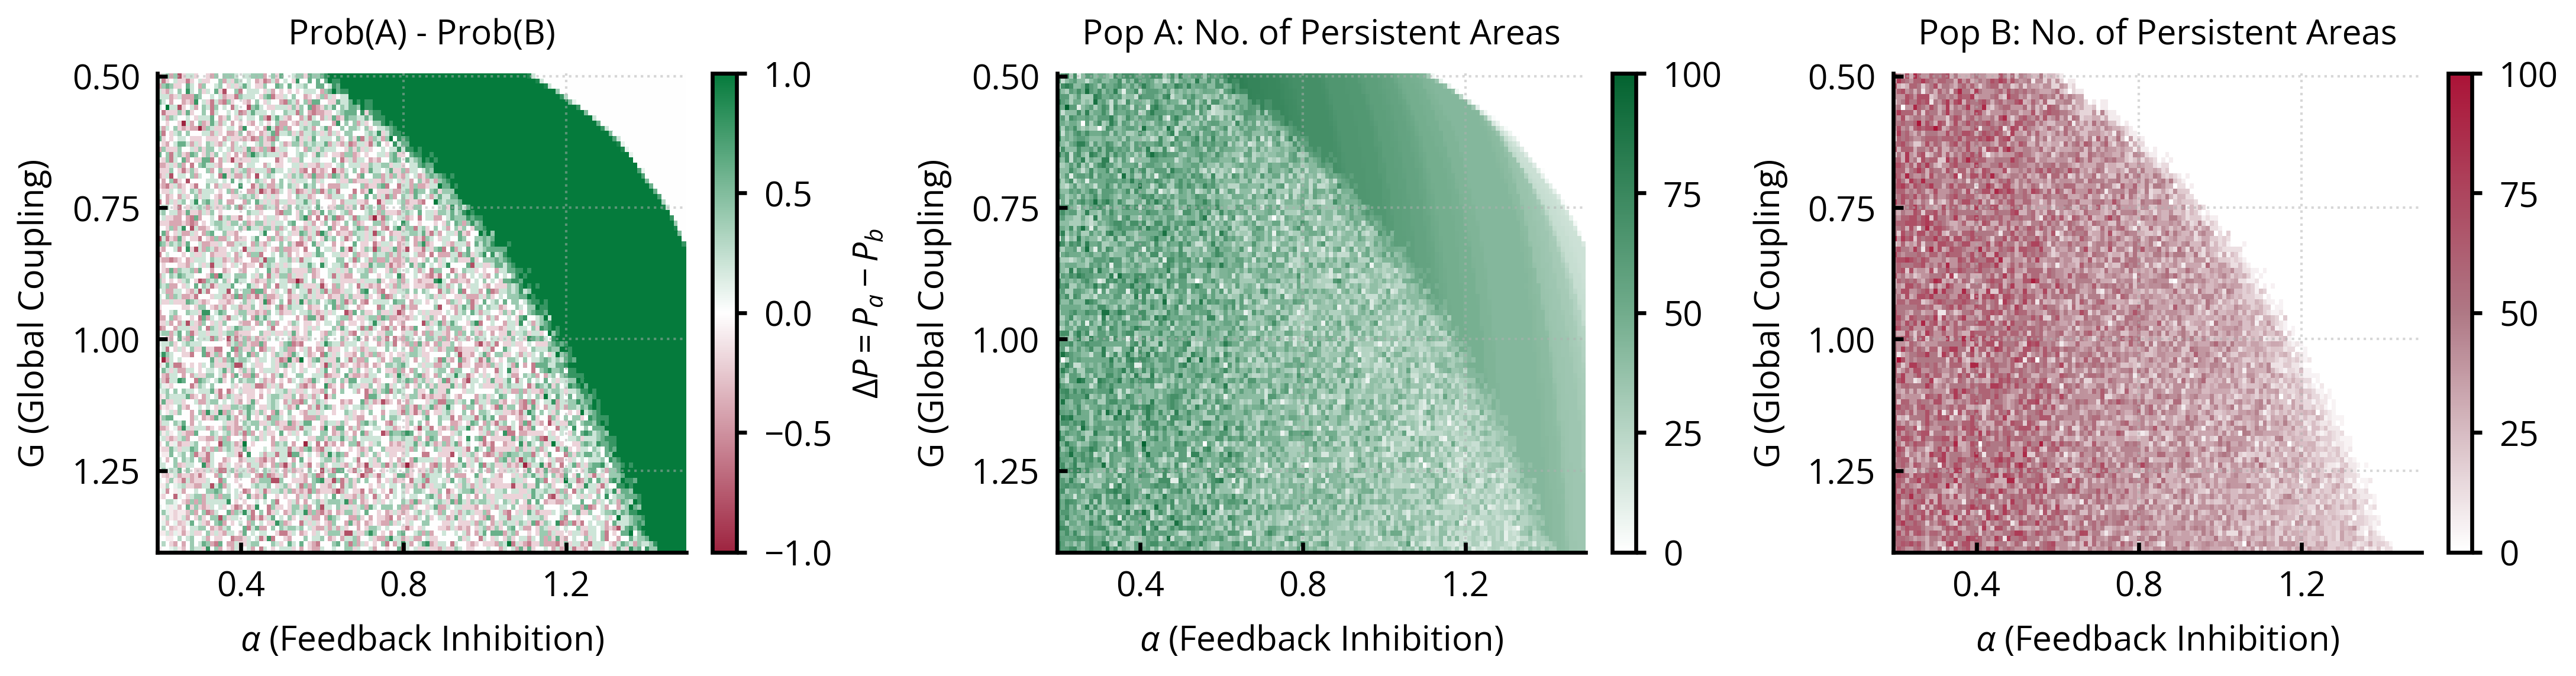

Journal-sized panel saved in: /home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3


In [8]:
# Journal-sized version of the panels produced by plot_forbidden_gap_analysis above:
# Pop A areas | Pop B areas | Prob(A) - Prob(B), all in one 18.4 x 4.8 cm figure.
# Same styling as the "Journal-sized phase-diagram panels" cell of ../../../../Figures/Figure_4.ipynb.
import os
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Applied only inside the "with" block below, so the rcParams set by the cells above
# (and by plot_forbidden_gap_analysis) are left as they are.
# Note: the 'science' style sets text.usetex = True, and LaTeX ignores font.family, so
# usetex has to be off for Open Sans to be used. The mathtext entries make the $\alpha$
# in the x label and the $\Delta P$ colorbar label render in Open Sans too.
panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Open Sans",
    "mathtext.it": "Open Sans:italic",
    "mathtext.bf": "Open Sans:bold",
    "mathtext.cal": "Open Sans:italic",
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
PANEL_W = 18.4 / CM   # full page width for the three maps together
PANEL_H = 4.8 / CM

csv_path = ('/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/'
            'g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3/'
            'persistent_activity_stats_all_runs.csv')
results_dir = ('/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/'
               'g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3')

# Local copy, same filtering as plot_forbidden_gap_analysis
df_panel = pd.read_csv(csv_path, delimiter=",", skipinitialspace=True)
df_panel = df_panel[df_panel['G'] <= 1.4]  # Simulation didn't work for some values above this

# Probability(A) = Prob(A Only) + Prob(A & B), same for B; recomputed here as in the function above
df_panel["Probability(A)"] = df_panel["Prob_A_Only"] + df_panel["Prob_A_B"]
df_panel["Probability(B)"] = df_panel["Prob_B_Only"] + df_panel["Prob_A_B"]
df_panel["ProbDiff(A-B)"] = df_panel["Probability(A)"] - df_panel["Probability(B)"]


def style_ax(ax, nbins=4):
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins))
    ax.grid(which='major', linestyle=':', alpha=0.5)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(top=False, right=False)


def style_cbar(cbar, nbins=4):
    cbar.locator = MaxNLocator(nbins)
    cbar.update_ticks()
    cbar.ax.minorticks_off()
    cbar.ax.tick_params(which='both', direction='out', length=2, width=0.8)


# The three maps, left to right. Each entry: column, title, colormap, colorbar label.
maps = [
    ("ProbDiff(A-B)", "Prob(A) - Prob(B)", cmaps_phase['pop_A_minus_B'],
     r'$\Delta P = P_a - P_b$'),
    ("MeanAreasA_uncond", "Pop A: No. of Persistent Areas", cmaps_phase['pop_A'], None),
    ("MeanAreasB_uncond", "Pop B: No. of Persistent Areas", cmaps_phase['pop_B'], None),
]

with mpl.rc_context(panel_style):
    # constrained_layout fits the three colorbars without changing the overall figure size
    fig, axes = plt.subplots(1, 3, figsize=(PANEL_W, PANEL_H), constrained_layout=True)

    for ax, (col, title, cmap, cbar_label) in zip(axes, maps):
        piv = df_panel.pivot(index="G", columns="alpha", values=col)
        im = ax.pcolor(piv.columns, piv.index, piv.values, cmap=cmap, shading='auto')
        ax.invert_yaxis()
        ax.set_title(title)
        ax.set_xlabel("$\\alpha$ (Feedback Inhibition)")
        ax.set_ylabel("G (Global Coupling)")
        style_ax(ax, nbins=4)

        cbar = fig.colorbar(im, ax=ax)
        if cbar_label:
            cbar.set_label(cbar_label)
        style_cbar(cbar, nbins=4)

    # no bbox_inches='tight', so the file keeps the exact 18.4 x 4.8 cm size
    fig.savefig(os.path.join(results_dir, 'phase_diagram_journal_panel.pdf'))
    fig.savefig(os.path.join(results_dir, 'phase_diagram_journal_panel.svg'))
    plt.show()

print("Journal-sized panel saved in:", results_dir)